# Assign SNPs to genes

In [2]:
rm(list=ls())
library(tidyverse)
library(magrittr)

# change these variables as needed
wdir = "/lustre/orion/syb111/proj-shared/Personal/abeyratnecr/switchgrass/sub_proj/snp2geneLD"
gwas_with_span_fn = paste0(wdir, '/fsnps/gwas_with_span.csv')
coord_to_genes_fn = paste0(wdir, '/s2g/coordinate_to_gene_assignments.txt')
# filtered_snps_dir = paste0(wdir, "/results/filtered_snps")
# trait_list_fn = paste0(wdir, '/results/gwas_trait_list.txt')
# window_list_fn = paste0(wdir, "/results/5000000_2500000.bed") # filename of the bed file with genomic intervals for LD estimation

setwd(wdir)

In [3]:
gwas_with_span <- read.csv(file=gwas_with_span_fn, header=T)

# check the chromosome names here. They need to match between gwas_with_span_fn and coord_to_genes_fn
gwas_with_span <- gwas_with_span %>% mutate(Chr = paste0('Chr', Chr)) # Only because switchgrass Chr names were different
dim(gwas_with_span)
head(gwas_with_span)

[1] 23486    16

,gwas_model,trait,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,Adjusted.P.value,Bonferroni_P.value,mod_fit,span,up_loc,down_loc
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
1,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01,0.9663583,8342,691618,708302
2,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01,0.9663583,8342,691618,708302
3,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01,0.9663583,8342,691618,708302
4,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,Chr01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02,0.9663583,8342,710324,727008
5,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,Chr01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02,0.9663583,8342,710324,727008
6,FarmCPU,ihf_panicle_emergence_2020_1,Chr01K_744204,Chr01K,744204,3.80e-16,0.14069264,231,1.230000e-10,-5.9991126,3.160000e-10,5.05e-09,0.9663583,8342,735862,752546


In [4]:
coordinate_to_genes <- read.table(file=coord_to_genes_fn, header=F)

# parsing required information out of the alignments
tmp_columns <- NULL
for (i in 1:nrow(coordinate_to_genes)) {
    tmp_val <- coordinate_to_genes$V12[i]
    tmp_list <- tmp_val %>% str_split(';') %>% unlist()
    tmp_columns <- rbind(tmp_columns, 
                         cbind(gene=tmp_list[1],
                               name=tmp_list[2],
                               gbkey=tmp_list[3]))
}


stopifnot(nrow(tmp_columns) == nrow(coordinate_to_genes))
c2g <- cbind(coordinate_to_genes[c(1:8, 10)], tmp_columns[,1])
colnames(c2g) <- c('Chr', 'up_loc', 'down_loc', 'Chr_gene', 'source', 'gbkey', 'gene_start', 'gene_end', 'strand', 'geneID')

# filter out all entries that are not genes
s2g_only <- c2g %>% filter(gbkey == 'gene')

dim(s2g_only)
head(s2g_only)

[1] 8197   10

,Chr,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID
,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,Chr01K,691618,708302,Chr01K,phytozomev13,gene,692799,699768,+,ID=Pavir.1KG006200.v5.1
2,Chr01K,691618,708302,Chr01K,phytozomev13,gene,700809,703351,+,ID=Pavir.1KG006500.v5.1
3,Chr01K,710324,727008,Chr01K,phytozomev13,gene,713227,714982,+,ID=Pavir.1KG006600.v5.1
4,Chr01K,710324,727008,Chr01K,phytozomev13,gene,720253,722976,+,ID=Pavir.1KG006801.v5.1
5,Chr01K,735862,752546,Chr01K,phytozomev13,gene,739569,740672,-,ID=Pavir.1KG007100.v5.1
6,Chr01K,735862,752546,Chr01K,phytozomev13,gene,743375,747127,-,ID=Pavir.1KG007300.v5.1


In [5]:
s2g_only %>% distinct() %>% dim()

# manually checked and all entries contained gbkey=Gene although this value was positioned differently in some lines
s2g_only$gbkey %>% unique()

[1] 8197   10

[1] "gene"

In [6]:
# Checking whether all filtered GWAS hits with span have genes assigned 
all(paste0(gwas_with_span$Chr, "_", gwas_with_span$up_loc, "_", gwas_with_span$down_loc) %in% paste0(s2g_only$Chr, "_", s2g_only$up_loc, "_", s2g_only$down_loc))

[1] FALSE

In [7]:
# Separating out the GWAS hits with genes assigned vs. not
entries_wo_genes <- NULL
gwas_with_genes <- NULL
for (i in 1:nrow(gwas_with_span)) {
    tmp_ <- s2g_only %>% 
    filter(Chr==gwas_with_span$Chr[i]) %>% 
    filter(up_loc==gwas_with_span$up_loc[i] & down_loc==gwas_with_span$down_loc[i])

    if (nrow(tmp_) == 0) {
        entries_wo_genes <- rbind(entries_wo_genes, gwas_with_span[i,])
    } else {
        merged_entries <- tmp_[,-1] %>%
        mutate(SNP = gwas_with_span$SNP[i],
               Chr = gwas_with_span$Chr[i],
               Pos = gwas_with_span$Pos[i],
               P.value = gwas_with_span$P.value[i],
               MAF = gwas_with_span$MAF[i],
               nobs = gwas_with_span$nobs[i],
               H.B.P.Value = gwas_with_span$H.B.P.Value[i],
               Effect = gwas_with_span$Effect[i],
               trait = gwas_with_span$trait[i],
               model = gwas_with_span$model[i],
               LD_decay_fit_R2 = gwas_with_span$mod_fit[i],
               span = gwas_with_span$span[i])
        gwas_with_genes <- bind_rows(gwas_with_genes, merged_entries)
    }
}
gwas_with_genes$geneID %<>% str_replace('ID=gene-', '')
dim(gwas_with_genes)
str(gwas_with_genes)

[1] 34315    20

'data.frame':	34315 obs. of  20 variables:
 $ up_loc         : int  691618 691618 691618 691618 691618 691618 710324 710324 710324 710324 ...
 $ down_loc       : int  708302 708302 708302 708302 708302 708302 727008 727008 727008 727008 ...
 $ Chr_gene       : chr  "Chr01K" "Chr01K" "Chr01K" "Chr01K" ...
 $ source         : chr  "phytozomev13" "phytozomev13" "phytozomev13" "phytozomev13" ...
 $ gbkey          : chr  "gene" "gene" "gene" "gene" ...
 $ gene_start     : int  692799 700809 692799 700809 692799 700809 713227 720253 713227 720253 ...
 $ gene_end       : int  699768 703351 699768 703351 699768 703351 714982 722976 714982 722976 ...
 $ strand         : chr  "+" "+" "+" "+" ...
 $ geneID         : chr  "ID=Pavir.1KG006200.v5.1" "ID=Pavir.1KG006500.v5.1" "ID=Pavir.1KG006200.v5.1" "ID=Pavir.1KG006500.v5.1" ...
 $ SNP            : chr  "Chr01K_699960" "Chr01K_699960" "Chr01K_699960" "Chr01K_699960" ...
 $ Chr            : chr  "Chr01K" "Chr01K" "Chr01K" "Chr01K" ...
 $ Pos        

In [8]:
entries_wo_genes %>% dim()
head(entries_wo_genes)

[1] 6192   16

,gwas_model,trait,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,Adjusted.P.value,Bonferroni_P.value,mod_fit,span,up_loc,down_loc
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
40,FarmCPU,ihf_tiller_count_2020_1,Chr01K_2490822,Chr01K,2490822,2.61e-09,0.11086957,230,0.000240255,-79.342758,0.000541232,0.0347,0.9551719,6558,2484264,2497380
41,FarmCPU,ihf_tiller_count_2020_1,Chr01K_2490822,Chr01K,2490822,2.61e-09,0.11086957,230,0.000240255,-79.342758,0.000541232,0.0347,0.9551719,6558,2484264,2497380
88,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071,0.001844253,0.0517,0.9698946,5322,4740271,4750915
89,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071,0.001844253,0.0517,0.9698946,5322,4740271,4750915
90,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071,0.001844253,0.0517,0.9698946,5322,4740271,4750915
91,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071,0.001844253,0.0517,0.9698946,5322,4740271,4750915


In [9]:
# check how many unique SNPs 
entries_wo_genes %>% pull(SNP) %>% unique() %>% length()
# write entries without associated genes for the ld span
write.table(entries_wo_genes[,1:10], paste0(wdir, '/s2g/gwas_hits_wo_genes_in_ld_span.txt'), quote=F, row.names=F)

[1] 1476

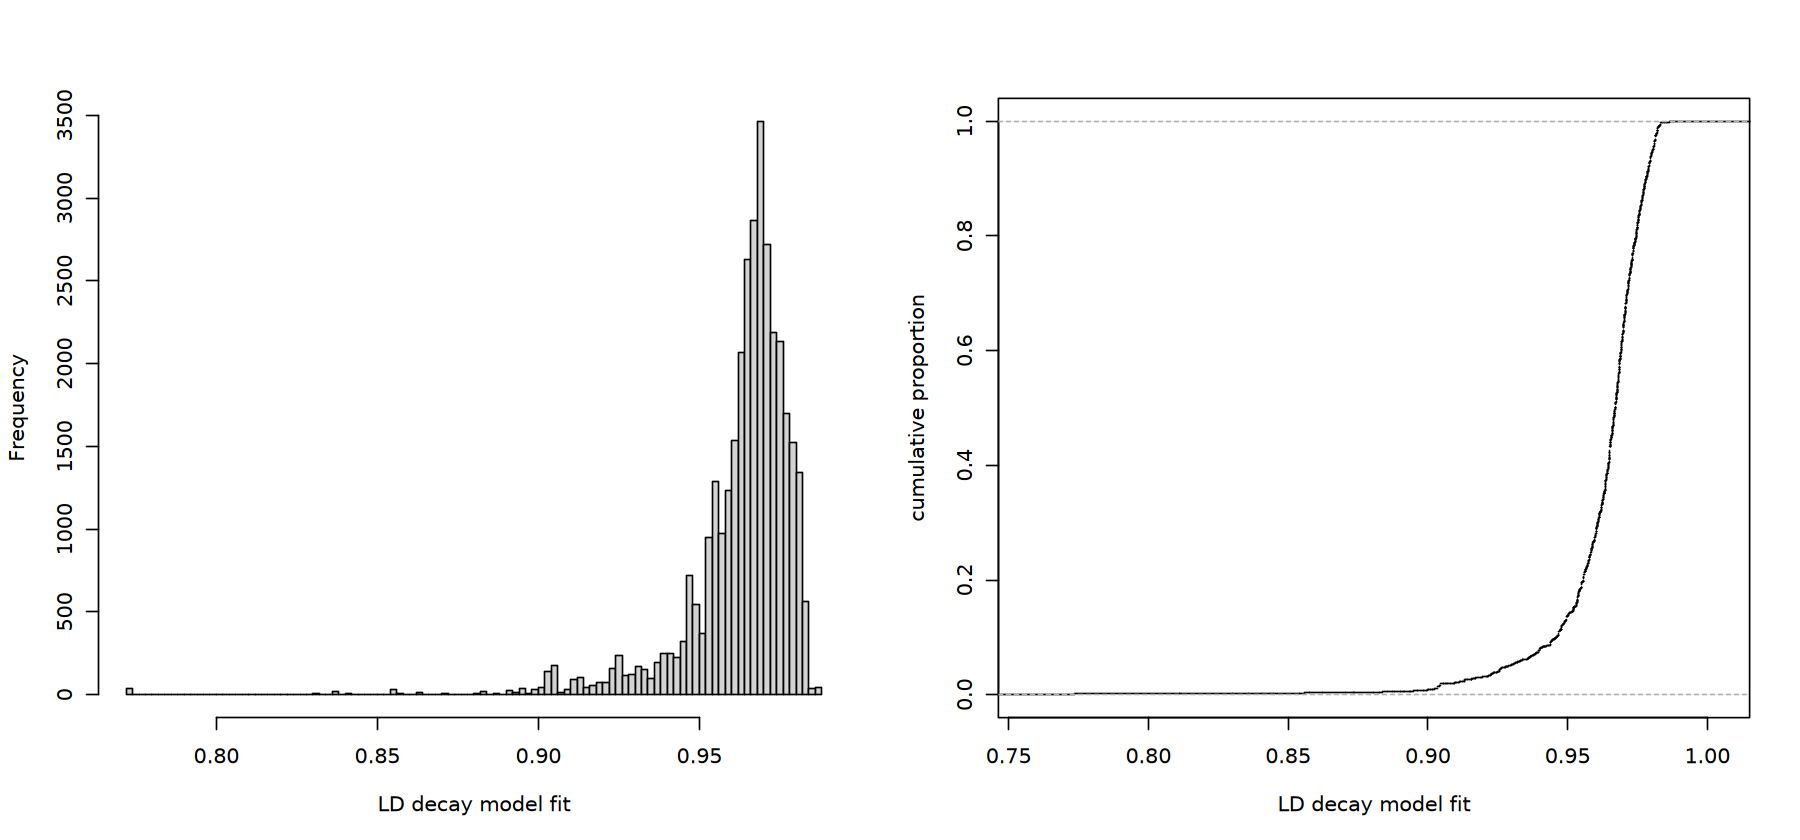

In [10]:
# visualize distribution of model fit for the windows
options(repr.plot.width=15)
op <- par(mfrow=c(1, 2))
hist(gwas_with_genes$LD_decay_fit_R2, breaks=100, main=NULL, xlab='LD decay model fit')
plot(ecdf(gwas_with_genes$LD_decay_fit_R2), main=NULL, xlab='LD decay model fit', ylab='cumulative proportion')
par(op)

In [11]:
# set a cut off for LD-decay model fit based on above plots
ld_decay_cut = 0.9 # User defined based on above plots
poor_ld_idx <- which(gwas_with_genes$LD_decay_fit_R2 < ld_decay_cut)
poor_ld_idx %>% length()

[1] 296

In [12]:
gwas_hits_in_poor_ld_regions <- gwas_with_genes[poor_ld_idx,1:10] %>% unique()
dim(gwas_hits_in_poor_ld_regions)
head(gwas_hits_in_poor_ld_regions)
write.table(gwas_hits_in_poor_ld_regions, file=paste0(wdir, '/s2g/gwas_hits_in_poor_ld_regions.txt'), quote=F, row.names=F)

[1] 77 10

,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID,SNP
,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>
2152,56528679,56550327,Chr01K,phytozomev13,gene,56544696,56548557,+,ID=Pavir.1KG555300.v5.1,Chr01K_56539503
2153,56528679,56550327,Chr01K,phytozomev13,gene,56548507,56551037,-,ID=Pavir.1KG555400.v5.1,Chr01K_56539503
2154,56528679,56550327,Chr01K,phytozomev13,gene,56525023,56544575,+,ID=Pavir.1KG555100.v5.1,Chr01K_56539503
2892,27316937,27348237,Chr02K,phytozomev13,gene,27334130,27335811,+,ID=Pavir.2KG052658.v5.1,Chr02K_27332587
5863,37026087,37043319,Chr03K,phytozomev13,gene,37025665,37027183,-,ID=Pavir.3KG392927.v5.1,Chr03K_37034703
5864,37026087,37043319,Chr03K,phytozomev13,gene,37028738,37029814,+,ID=Pavir.3KG392954.v5.1,Chr03K_37034703


In [13]:
# Write correct assignemnts to file
snp2genes <- gwas_with_genes[-(poor_ld_idx),]
head(snp2genes)
write.table(snp2genes, paste0(wdir, '/s2g/snp2genes_based_on_ld_decay.txt'), quote=F, row.names=F)

,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,trait,LD_decay_fit_R2,span
,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<int>
1,691618,708302,Chr01K,phytozomev13,gene,692799,699768,+,ID=Pavir.1KG006200.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342
2,691618,708302,Chr01K,phytozomev13,gene,700809,703351,+,ID=Pavir.1KG006500.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342
3,691618,708302,Chr01K,phytozomev13,gene,692799,699768,+,ID=Pavir.1KG006200.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342
4,691618,708302,Chr01K,phytozomev13,gene,700809,703351,+,ID=Pavir.1KG006500.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342
5,691618,708302,Chr01K,phytozomev13,gene,692799,699768,+,ID=Pavir.1KG006200.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342
6,691618,708302,Chr01K,phytozomev13,gene,700809,703351,+,ID=Pavir.1KG006500.v5.1,Chr01K_699960,Chr01K,699960,2.67e-08,0.09641256,223,0.001230638,-0.8497491,ihf_total_dry_biomass_kg_2021_1,0.9663583,8342


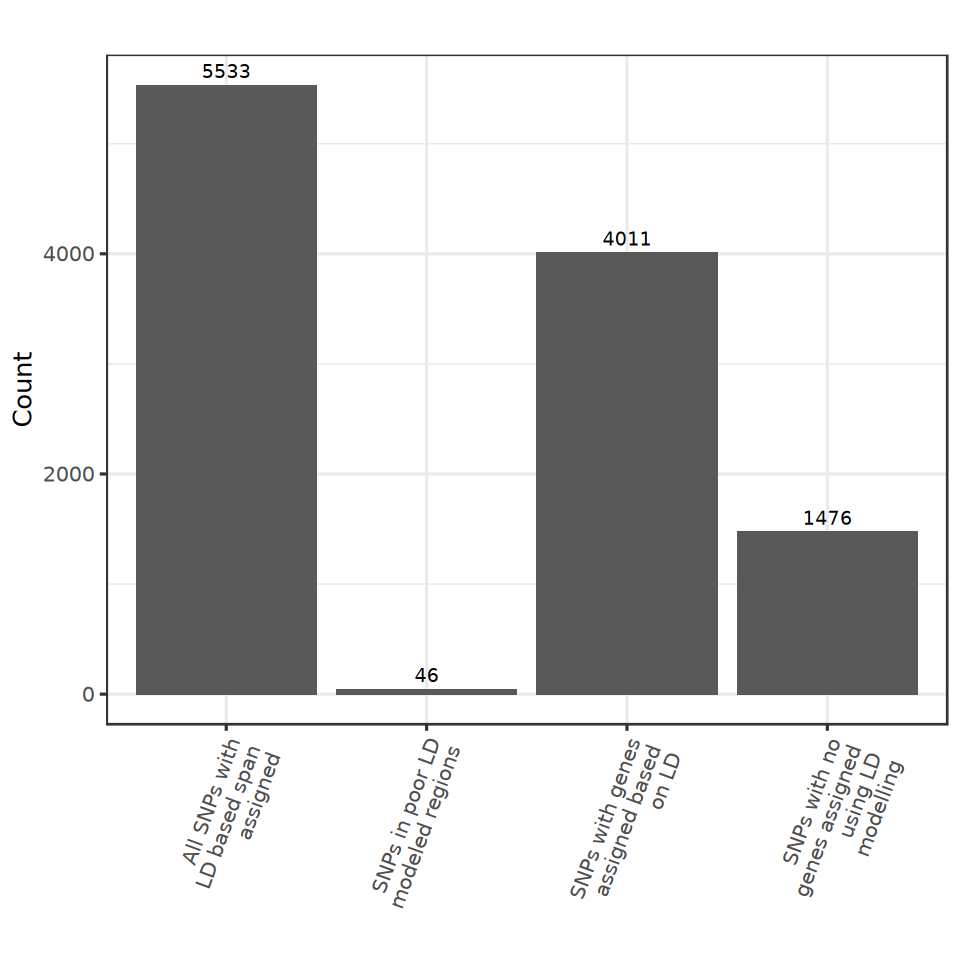

In [24]:
# Break-down of SNPs that got dropped at each stage
ld_poor_snps = gwas_with_genes[(poor_ld_idx),] %>% pull(SNP) %>% unique()
ld_s2g_snps = snp2genes %>% pull(SNP) %>% unique()
no_genes_in_span_snps = entries_wo_genes %>% pull(SNP) %>% unique()
all_snps_with_span = gwas_with_span %>% pull(SNP) %>% unique()

descr = c('SNPs in poor LD modeled regions', 
          'SNPs with genes assigned based on LD', 
          'SNPs with no genes assigned using LD modelling', 
          'All SNPs with LD based span assigned')
count = c(length(ld_poor_snps),
          length(ld_s2g_snps),
          length(no_genes_in_span_snps),
          length(all_snps_with_span))

SNP_brkdwn = cbind(descr, count) %>% data.frame()

options(repr.plot.width=8, repr.plot.height=8)
SNP_brkdwn %>% 
  mutate(count = as.numeric(count),
         descr = str_wrap(descr, width = 15)) %>%  
  ggplot(aes(x = descr, y = count)) +
  geom_bar(stat = "identity") + 
  geom_text(aes(label = count), 
            position = position_dodge(width = 0.8), 
            vjust = -0.5, 
            size = 4) +
  theme_bw(base_size = 15) +
  labs(x = "", y = "Count", fill = NULL, title = "") +
  theme(axis.text.x = element_text(angle = 70, vjust = 1, hjust = 1), 
        legend.position = "right")

[1] 44  2

[1] 44  2

[1] 44  3

,trait,SNPs,genes
,<chr>,<int>,<int>
1,ihf_anthracnose_0_5_2020_1,11,19
2,ihf_crown_area_cm_2021_2,90,206
3,ihf_fusarium_0_1_2020_1,172,275
4,ihf_leaf_chlorophyll_2021_1,99,187
5,ihf_leaf_chlorophyll_2021_2,72,145
6,ihf_lodging_0_5_2019_1,73,154


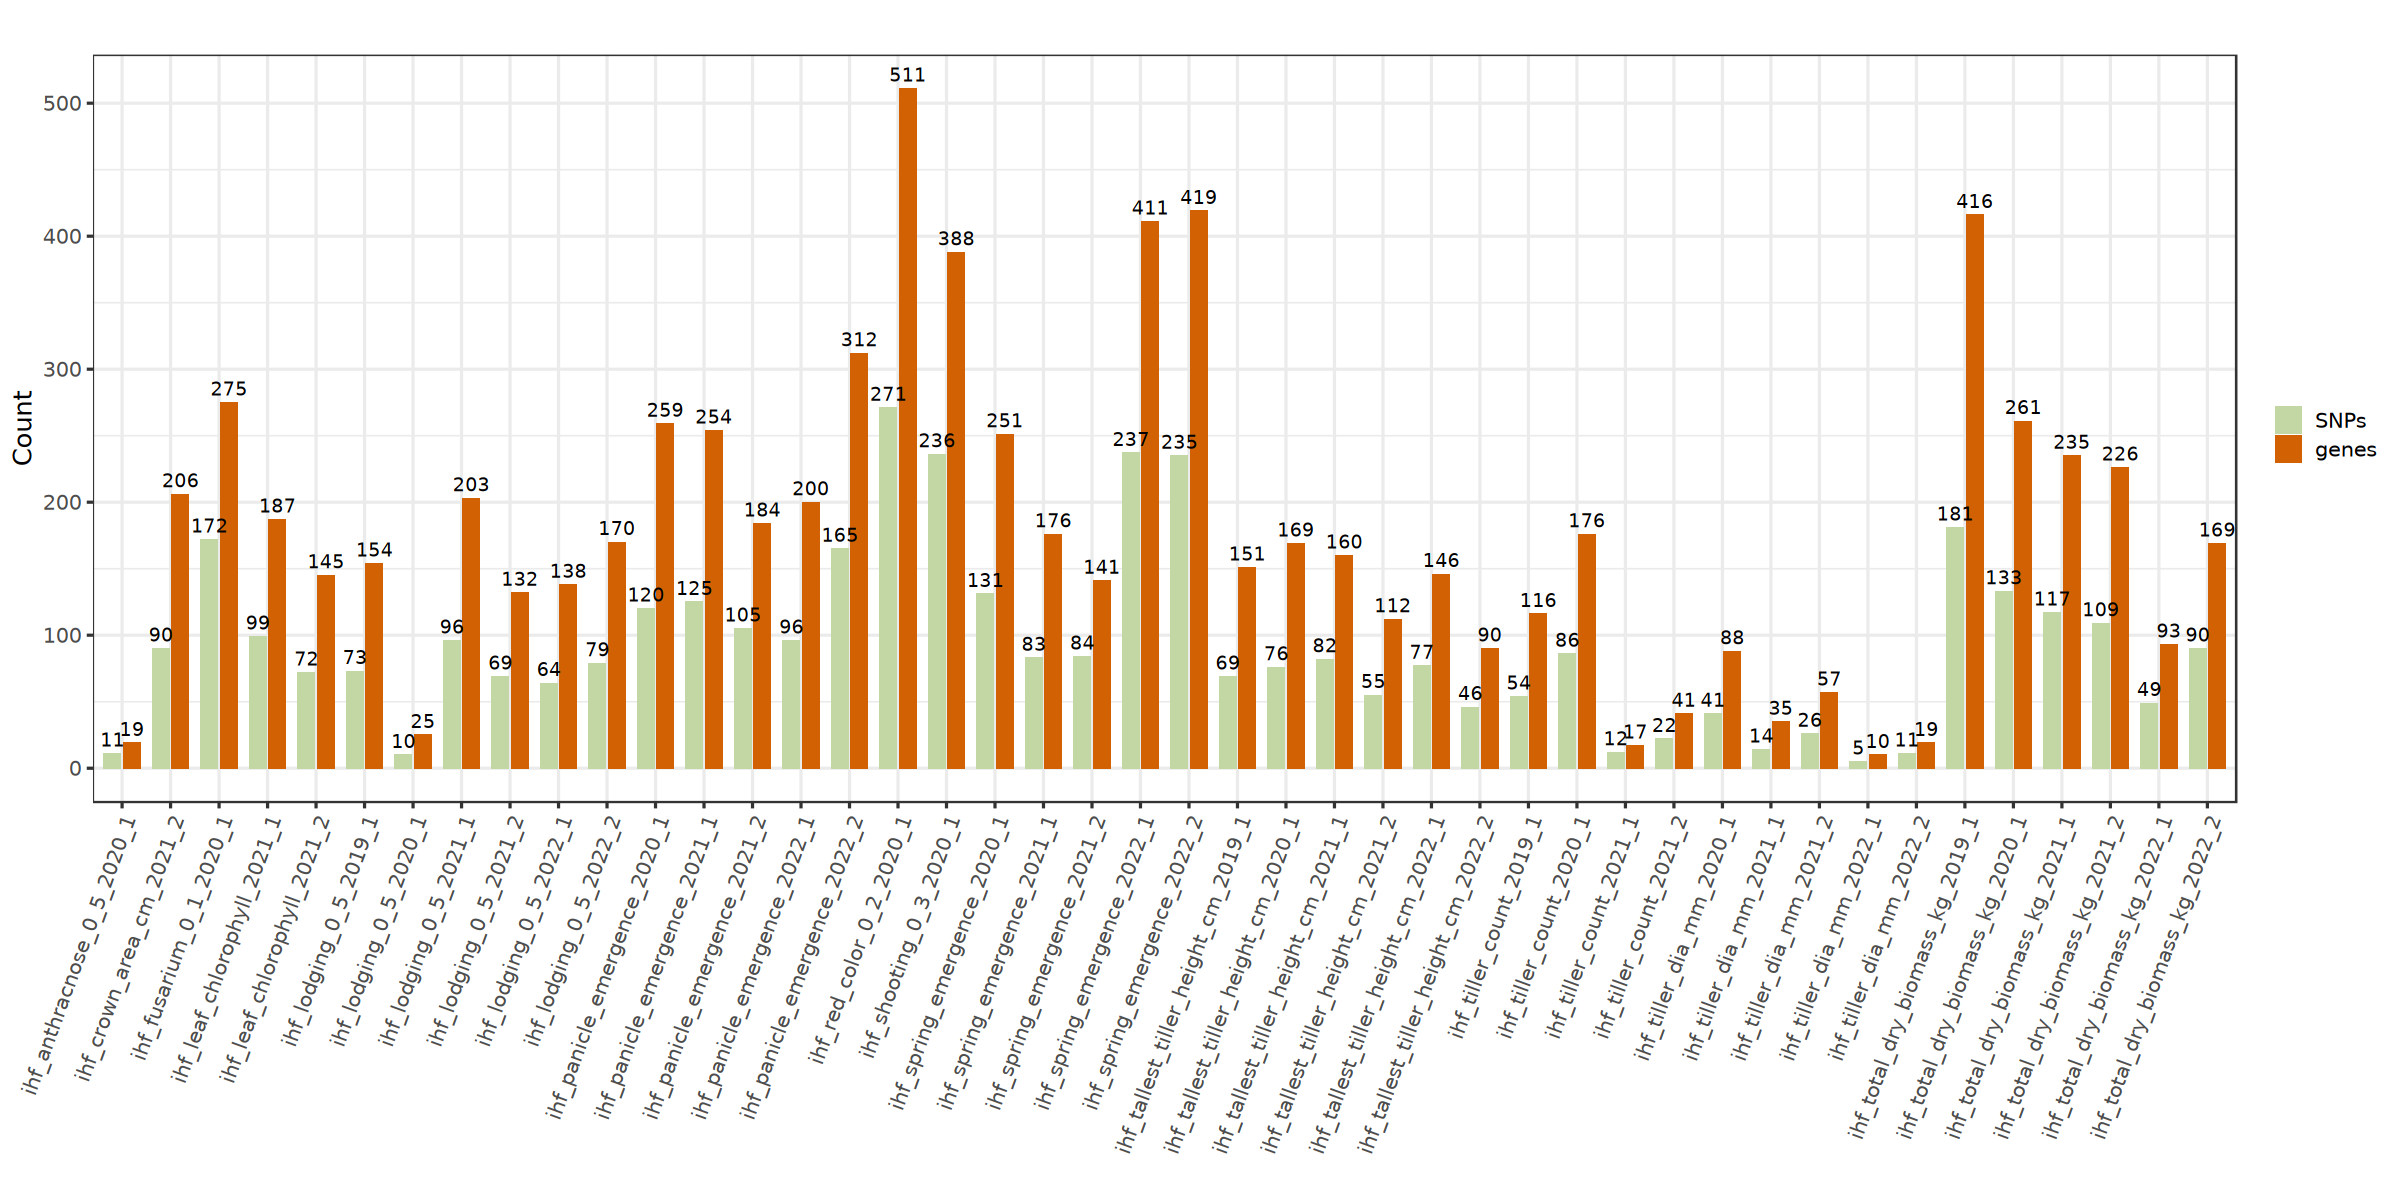

In [15]:
options(repr.plot.width=20, repr.plot.height=10)

SNP_freq <- snp2genes %>% 
select(SNP, trait) %>% 
distinct() %>% 
group_by(trait) %>% 
summarise(SNPs=n())

gene_freq <- snp2genes %>% 
select(geneID, trait) %>% 
distinct() %>% 
group_by(trait) %>% 
summarise(genes=n())

dim(SNP_freq)
dim(gene_freq)

snp2genes_stat = merge(SNP_freq, gene_freq, by='trait')
dim(snp2genes_stat)
head(snp2genes_stat)

snp2genes_stat %>% 
pivot_longer(-1, names_to='type', values_to='freq') %>% 
ggplot(aes(x=trait, y=freq, fill=type)) +
geom_bar(stat="identity", position=position_dodge(width = 0.8), width=0.7) + 
scale_fill_manual(values = c("#C3D7A4", "#D16103")) +
geom_text(aes(label = freq), 
            position = position_dodge(width = 0.8), 
            vjust = -0.5, 
            size = 4) +
theme_bw(base_size=15) +
labs(x="", y="Count", fill=NULL, title="") +
theme(axis.text.x=element_text(angle=70, vjust=1, hjust=1), legend.position="right")

In [16]:
# writing SNPs that needs to be assigned genes based on closest distance
entries_wo_genes[,1:10] %>% head()

,gwas_model,trait,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>
40,FarmCPU,ihf_tiller_count_2020_1,Chr01K_2490822,Chr01K,2490822,2.61e-09,0.11086957,230,0.000240255,-79.342758
41,FarmCPU,ihf_tiller_count_2020_1,Chr01K_2490822,Chr01K,2490822,2.61e-09,0.11086957,230,0.000240255,-79.342758
88,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071
89,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071
90,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071
91,BLINK,ihf_leaf_chlorophyll_2021_2,Chr01K_4745593,Chr01K,4745593,3.89e-09,0.07175926,216,0.000626795,2.718071


In [17]:
gwas_hits_in_poor_ld_regions %>% head()

,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID,SNP
,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>
2152,56528679,56550327,Chr01K,phytozomev13,gene,56544696,56548557,+,ID=Pavir.1KG555300.v5.1,Chr01K_56539503
2153,56528679,56550327,Chr01K,phytozomev13,gene,56548507,56551037,-,ID=Pavir.1KG555400.v5.1,Chr01K_56539503
2154,56528679,56550327,Chr01K,phytozomev13,gene,56525023,56544575,+,ID=Pavir.1KG555100.v5.1,Chr01K_56539503
2892,27316937,27348237,Chr02K,phytozomev13,gene,27334130,27335811,+,ID=Pavir.2KG052658.v5.1,Chr02K_27332587
5863,37026087,37043319,Chr03K,phytozomev13,gene,37025665,37027183,-,ID=Pavir.3KG392927.v5.1,Chr03K_37034703
5864,37026087,37043319,Chr03K,phytozomev13,gene,37028738,37029814,+,ID=Pavir.3KG392954.v5.1,Chr03K_37034703


In [19]:
# reading the full list of GWA hits
snplist_fn = paste0(wdir, "/snp2genes_IronHorseFarm_GWASout_with_AT_annotation_cra.txt")
GWAS_hits <- read.table(file=snplist_fn, header=TRUE)
head(GWAS_hits)

,gwas_model,trait,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,Adjusted.P.value,Bonferroni_P.value
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
2,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
3,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
4,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02
5,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02
6,FarmCPU,ihf_panicle_emergence_2020_1,Chr01K_744204,01K,744204,3.80e-16,0.14069264,231,1.230000e-10,-5.9991126,3.160000e-10,5.05e-09


In [29]:
# Below should be all zeros if the pipeline ran correctly
sum(ld_poor_snps %in% no_genes_in_span_snps)
sum(ld_poor_snps %in% ld_s2g_snps)
sum(no_genes_in_span_snps %in% ld_s2g_snps)

[1] 0

[1] 0

[1] 0

In [32]:
# These should all equal the number of total SNPs
sum(all_snps_with_span %in% unique(GWAS_hits$SNP))
sum(unique(GWAS_hits$SNP) %in% all_snps_with_span )
length(all_snps_with_span)

[1] 5533

[1] 5533

[1] 5533

In [36]:
hits_for_closest_gene <- GWAS_hits %>% filter(!SNP %in% c(no_genes_in_span_snps, ld_poor_snps))
hits_for_closest_gene %>% dim()
hits_for_closest_gene %>% head()


[1] 17129    12

,gwas_model,trait,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,Adjusted.P.value,Bonferroni_P.value
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
2,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
3,BLINK,ihf_total_dry_biomass_kg_2021_1,Chr01K_699960,01K,699960,2.67e-08,0.09641256,223,1.230638e-03,-0.8497491,5.914254e-03,3.55e-01
4,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02
5,BLINK,ihf_shooting_0_3_2020_1,Chr01K_718666,01K,718666,1.30e-09,0.06926407,231,2.314220e-04,0.4236989,1.793200e-04,1.73e-02
6,FarmCPU,ihf_panicle_emergence_2020_1,Chr01K_744204,01K,744204,3.80e-16,0.14069264,231,1.230000e-10,-5.9991126,3.160000e-10,5.05e-09


In [41]:
# arranging data as per GAPIT format and rewriting to another file for subsequent script
hits_for_closest_gene_reformt <- hits_for_closest_gene %>% select(SNP, Chr, Pos, P.value, MAF, nobs, H.B.P.Value, Effect)
write.csv(hits_for_closest_gene_reformt, file=paste0(wdir, '/s2g/gwas_hits_for_closest_gene_reformt.csv'), row.names=F, quote=F)

In [ ]:
# END